# 1. Import Libraries & Load Data

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
# Note: Check your path
df = pd.read_csv("C:\\Users\\user\\Documents\\GitHub\\ai4i-predictive-maintenance\\original_data\\not_clean_data.csv")

# Display the first 5 rows
display(df.head())

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,2568,L49747,L,299.4,309.1,1766.0,24.6,158.0,0,0,0,0,0,0
1,9222,M24081,M,297.8,309.0,1675.0,NaN,110.0,0,0,0,0,0,0
2,8408,L55587,L,NaN,309.5,1357.0,50.1,125.0,0,0,0,0,0,0
3,6023,L53202,L,300.7,310.9,NaN,39.4,61.0,0,0,0,0,0,0
4,2034,H31447,H,298.8,308.5,1359.0,47.6,NaN,0,0,0,0,0,0


# 2. Analysis of Data Quality (Before Cleaning)

In [65]:
# Number of (rows,columns)
print(df.shape)

# All columns match
print(f"Total Exact Duplicates: {df.duplicated().sum()}")

# Same ID
print(f"Total UDI Duplicates: {df.duplicated(subset=['UDI']).sum()}\n")

# Missing Values
print("    Missing Values    ")
print(df.isnull().sum())

# Summary Statistics before Cleaning
print("    Summary Statistics (Before)    ")
display(df.describe())

# To check data column type
display(df.info())

(10200, 14)
Total Exact Duplicates: 147
Total UDI Duplicates: 200

    Missing Values    
UDI                           0
Product ID                    0
Type                          0
Air temperature [K]        1585
Process temperature [K]    1572
Rotational speed [rpm]     1549
Torque [Nm]                1573
Tool wear [min]            1585
Machine failure               0
TWF                           0
HDF                           0
PWF                           0
OSF                           0
RNF                           0
dtype: int64
    Summary Statistics (Before)    


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10200.000000,8615.000000,8628.000000,8651.000000,8627.000000,8615.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000,10200.000000
mean,4997.302843,300.177249,310.181027,1572.198012,40.336050,109.415206,0.033529,0.004608,0.011275,0.009314,0.009804,0.001863
std,2887.603614,11.485850,11.927002,1678.111224,19.081356,98.918808,0.180023,0.067728,0.105586,0.096062,0.098533,0.043121
min,1.000000,150.000000,100.000000,-100.000000,-50.000000,-20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2489.750000,298.300000,308.800000,1422.000000,33.300000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4991.500000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7500.250000,301.500000,311.100000,1612.000000,46.800000,163.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,10000.000000,999.000000,1000.000000,100000.000000,1000.000000,5000.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


<class 'pandas.DataFrame'>
RangeIndex: 10200 entries, 0 to 10199
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10200 non-null  int64  
 1   Product ID               10200 non-null  str    
 2   Type                     10200 non-null  str    
 3   Air temperature [K]      8615 non-null   float64
 4   Process temperature [K]  8628 non-null   float64
 5   Rotational speed [rpm]   8651 non-null   float64
 6   Torque [Nm]              8627 non-null   float64
 7   Tool wear [min]          8615 non-null   float64
 8   Machine failure          10200 non-null  int64  
 9   TWF                      10200 non-null  int64  
 10  HDF                      10200 non-null  int64  
 11  PWF                      10200 non-null  int64  
 12  OSF                      10200 non-null  int64  
 13  RNF                      10200 non-null  int64  
dtypes: float64(5), int64(7), str(2)
m

None

# 3. Handling Duplicates

In [66]:
# Count NaNs for each row
numeric_cols = ["Air temperature [K]",
                "Process temperature [K]",
                "Rotational speed [rpm]",
                "Torque [Nm]",
                "Tool wear [min]"]

df['_nan_count'] = df[numeric_cols].isnull().sum(axis=1)

# Sort by UDI and NaN count, then drop duplicates keeping the most complete row
df = df.sort_values(by=['UDI', '_nan_count'])
df = df.drop_duplicates(subset='UDI', keep='first')

# Drop the temporary column and reset index
df = df.drop(columns=['_nan_count']).sort_values('UDI').reset_index(drop=True)

# (rows,columns) after removing duplicates
print(df.shape)

(10000, 14)


# 4. Detecting & Handling Outliers

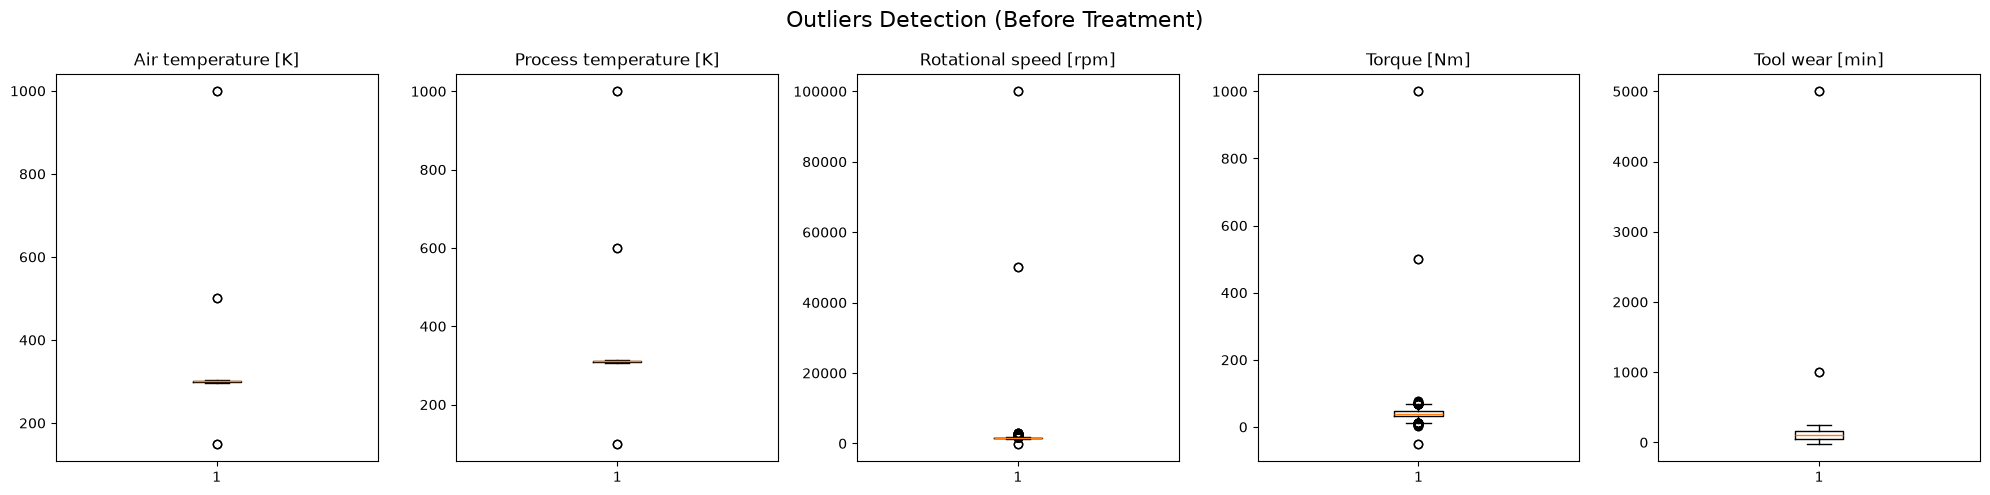

Impossible values have been treated as missing data (NaN) to be imputed in the next step.


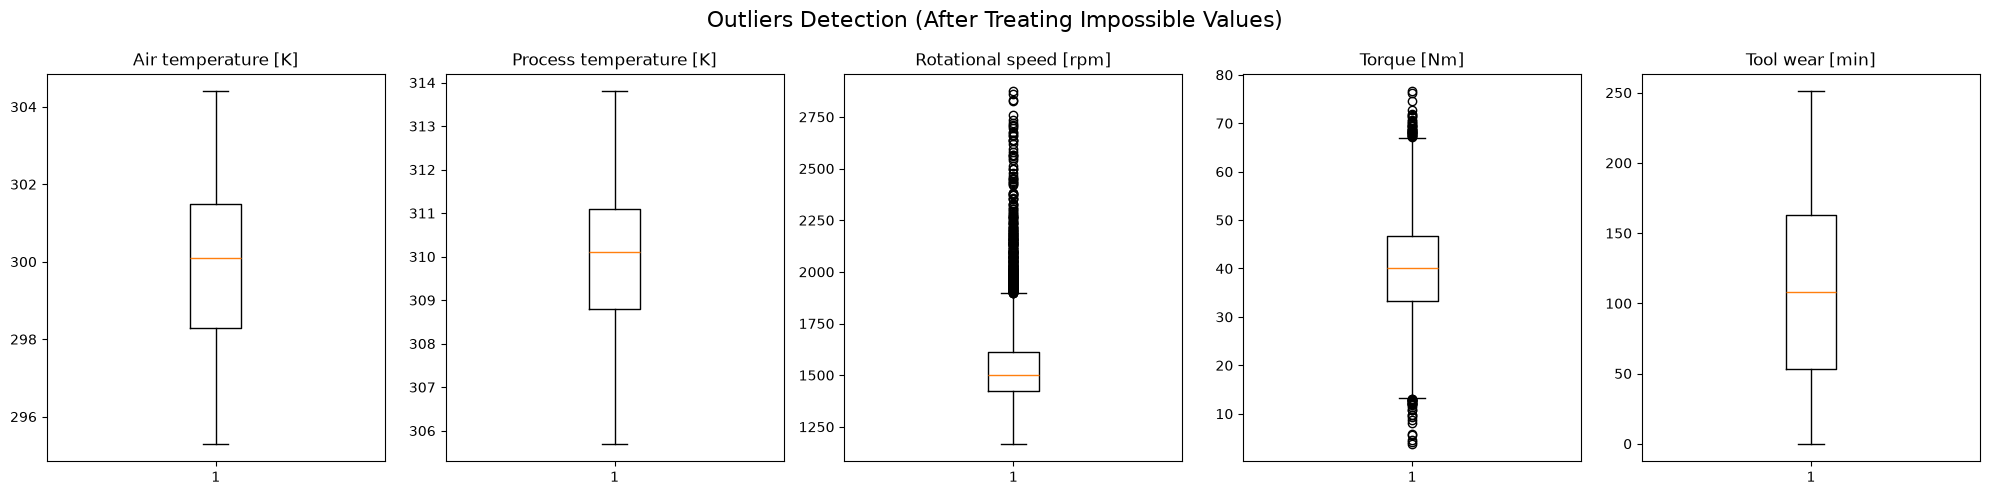

In [67]:
# Visualize Outliers Before Treatment
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Outliers Detection (Before Treatment)", fontsize=16)

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df[col].dropna())
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

# Decision: Replace impossible physical values with NaN instead of clipping all statistical outliers.
# Reason: In Predictive Maintenance, statistical outliers (like high torque) are actual symptoms of machine failure. Clipping them would hide failures. However, values like -20 min tool wear or 999K temp are impossible sensor errors.

limits = {
    "Air temperature [K]": (280, 320),
    "Process temperature [K]": (290, 330),
    "Rotational speed [rpm]": (1, 5000),
    "Torque [Nm]": (0.1, 100),
    "Tool wear [min]": (0, 300)
}

for col, (lo, hi) in limits.items():
    df.loc[(df[col] < lo) | (df[col] > hi), col] = np.nan

print("Impossible values have been treated as missing data (NaN) to be imputed in the next step.")


# Visualize Outliers Before Treatment Impossible Values
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Outliers Detection (After Treating Impossible Values)", fontsize=16)

for i, col in enumerate(numeric_cols):
    # dropna() is required because we just converted impossible values to NaN
    axes[i].boxplot(df[col].dropna())
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

# 5. Handling Missing Values

In [68]:
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after:")
print(df[numeric_cols].isnull().sum())

Missing values after:
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64


# 6. Fixing Incorrect Data Types

In [69]:
for col in ["Rotational speed [rpm]", "Tool wear [min]"]:
    df[col] = df[col].round().astype(int)

print(df[["Rotational speed [rpm]", "Tool wear [min]"]].dtypes)

Rotational speed [rpm]    int64
Tool wear [min]           int64
dtype: object


# 7. Summary Statistics (After Cleaning) & Export

In [70]:
print("    Data Quality Check (After Cleaning)    ")
print(df.shape)
print(f"Total Missing Values: {df.isnull().sum().sum()}")
print(f"Total UDI Duplicates: {df.duplicated(subset=['UDI']).sum()}\n")

print("    Summary Statistics (After)    ")
display(df.describe())

display(df.info())

# Save the final cleaned dataset
df.to_csv("C:\\Users\\user\\Documents\\GitHub\\ai4i-predictive-maintenance\\original_data\\cleaned_data.csv", index=False)
print("\nCleaned dataset saved successfully!")

    Data Quality Check (After Cleaning)    
(10000, 14)
Total Missing Values: 0
Total UDI Duplicates: 0

    Summary Statistics (After)    


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.020350,310.020900,1533.356300,40.032100,108.085400,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,1.841837,1.363114,165.329447,9.185988,58.495028,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.600000,309.100000,1436.750000,34.600000,63.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.200000,310.900000,1586.000000,45.500000,153.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.400000,313.800000,2874.000000,76.600000,251.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

None


Cleaned dataset saved successfully!
